In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_csv("/Users/shoukkathali/Downloads/car_age_price.csv")

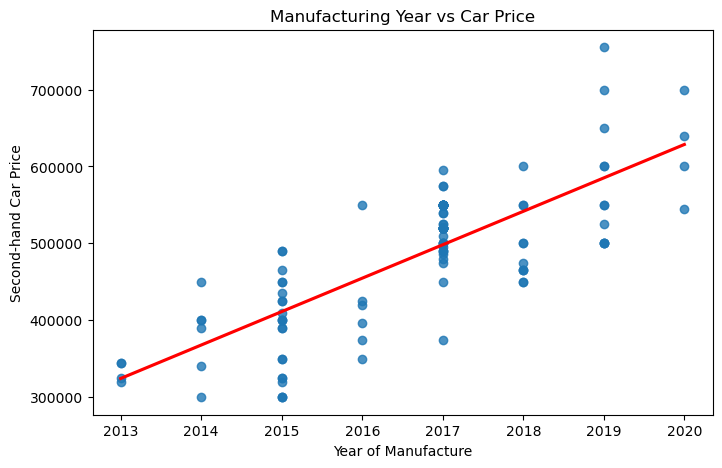

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.regplot(
    x='Year',
    y='Price',
    data=df,
    ci=None,
    line_kws={'color': 'red'}
)

plt.title('Manufacturing Year vs Car Price')
plt.xlabel('Year of Manufacture')
plt.ylabel('Second-hand Car Price')
plt.show()

In [4]:
df.head()

,Year,Price
0,2018,465000
1,2019,755000
2,2019,700000
3,2018,465000
4,2018,465000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Year    112 non-null    int64
 1   Price   112 non-null    int64
dtypes: int64(2)
memory usage: 1.9 KB


In [6]:
df.describe()

,Year,Price
count,112.000000,112.000000
mean,2016.669643,483866.044643
std,1.629616,91217.450533
min,2013.000000,300000.000000
25%,2015.000000,423750.000000
50%,2017.000000,500000.000000
75%,2017.000000,550000.000000
max,2020.000000,755000.000000


In [7]:
X = df[['Year']]
y = df['Price']

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [9]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
lr_pred = lr_model.predict(X_test)

In [11]:
print("R2 Score:", r2_score(y_test, lr_pred))
print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))

R2 Score: 0.36759313425902185
MAE: 53534.77957001264
RMSE: 65779.22359552195


In [12]:
lasso_model = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, random_state=42, max_iter=100000)
)

lasso_model.fit(X_train, y_train)

,steps,"[('standardscaler', ...), ('lassocv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,eps,0.001
,n_alphas,'deprecated'
,alphas,'warn'
,fit_intercept,True


In [13]:
lasso_pred = lasso_model.predict(X_test)

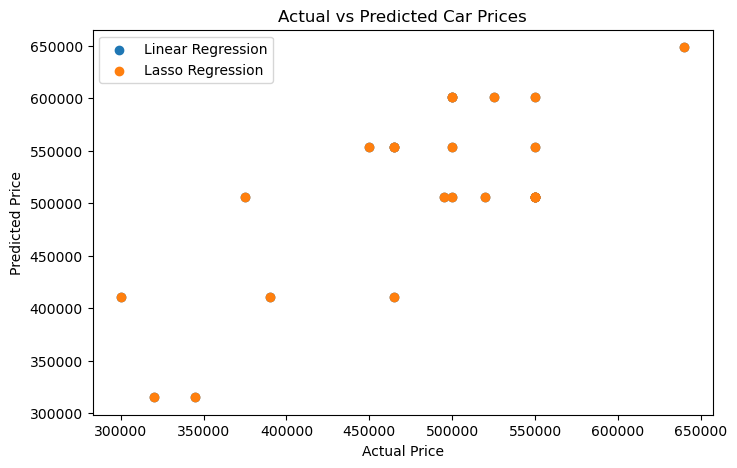

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, lr_pred, label='Linear Regression')
plt.scatter(y_test, lasso_pred, label='Lasso Regression')

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Car Prices')

plt.legend()
plt.show()

In [15]:
print("Linear Regression R2:", r2_score(y_test, lr_pred))
print("Lasso Regression R2:", r2_score(y_test, lasso_pred))

Linear Regression R2: 0.36759313425902185
Lasso Regression R2: 0.3683766967396165


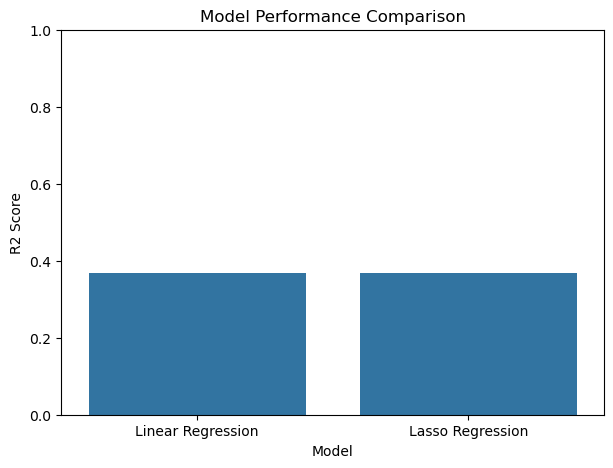

In [16]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Lasso Regression'],
    'R2 Score': [
        r2_score(y_test, lr_pred),
        r2_score(y_test, lasso_pred)
    ]
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=results,
    x='Model',
    y='R2 Score'
)

plt.title('Model Performance Comparison')
plt.ylabel('R2 Score')
plt.ylim(0, 1)
plt.show()

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=results,
    x='Model',
    y='R2 Score'
)

plt.title('Model Performance Comparison')
plt.ylabel('R2 Score')
plt.ylim(0, 1)
plt.show()

In [17]:
print("R2 Score:", r2_score(y_test, lasso_pred))
print("MAE:", mean_absolute_error(y_test, lasso_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lasso_pred)))

R2 Score: 0.3683766967396165
MAE: 53482.89158038061
RMSE: 65738.46019644287


In [18]:
print("Best Alpha:", lasso_model.named_steps['lassocv'].alpha_)

Best Alpha: 74.1526379221856


In [19]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Lasso Regression'],
    'R2 Score': [
        r2_score(y_test, lr_pred),
        r2_score(y_test, lasso_pred)
    ],
    'MAE': [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, lasso_pred)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, lasso_pred))
    ]
})

results

,Model,R2 Score,MAE,RMSE
0,Linear Regression,0.367593,53534.77957,65779.223596
1,Lasso Regression,0.368377,53482.89158,65738.460196


In [20]:
final_model = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, random_state=42, max_iter=100000)
)

final_model.fit(X, y)

,steps,"[('standardscaler', ...), ('lassocv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,eps,0.001
,n_alphas,'deprecated'
,alphas,'warn'
,fit_intercept,True


In [21]:
new_car = pd.DataFrame({'Year': [2022]})

predicted_price = final_model.predict(new_car)

print("Predicted price:", predicted_price[0])

Predicted price: 715256.4564759013
